# Seeq use case research pipeline: walkthrough

Stage by stage on the snapshots: discover pages from Seeq's sitemap, read the tracker, simulate the scheduled stages, parse the walkthroughs' Formula expressions and audit their check labels, then build the review page.

*Public Seeq pages only, summarised in our own words. Not affiliated with Seeq.*

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
import pandas as pd
pd.set_option('display.max_colwidth', 110)

## 1. Discovery: sitemap against the tracker

In [2]:
from src.data.load_data import load_tracker, load_sitemap, load_section_counts
from src.discovery.sitemap import parse_sitemap, discover
tracker = load_tracker()
rows = parse_sitemap(load_sitemap('use-case')) + parse_sitemap(load_sitemap('success-story'))
updated, report = discover(rows, tracker, today='2026-10-24')
print(load_section_counts()['resource_sections'])
print('new:', [n['Title'] for n in report['new']])
pd.DataFrame(report['skipped'])

{'use-case': 85, 'success-story': 18, 'post': 76, 'download': 33, 'event': 8, 'webinar': 34, 'video': 179}
new: ['Seeq international paper international papers dynamic ai driven decision intelligence layer']


,url,reason
0,https://www.seeq.com/resources/use-cases/minimize-vented-steam-in-dual-boiler-system-draft/,draft copy of another page
1,https://www.seeq.com/wp-content/uploads/2026/08/SB_Top-5-Use-Cases-for-FB.pdf#new_tab,"file link, not a page"


## 2. The tracker and the scheduled stages

In [3]:
from src.tracker.stages import funnel, simulate, reset_for_simulation
funnel(tracker)

{'tracked': 100,
 'use_cases': 83,
 'success_stories': 17,
 'extracted': 99,
 'notebooks': 82,
 'decks': 82,
 'published': 83,
 'walkthroughs': 78}

In [4]:
sim = simulate(reset_for_simulation(tracker))
print(len(sim), 'days to clear the backlog at 10 extracts, 3 notebooks and 3 decks a day')
sim.head(5)

28 days to clear the backlog at 10 extracts, 3 notebooks and 3 decks a day


,day,extract,notebook,deck,publish
0,1,10,3,3,3
1,2,10,3,3,3
2,3,10,3,3,3
3,4,10,3,3,3
4,5,10,3,3,3


## 3. Parse the Formula expressions

In [5]:
from src.data.load_data import load_walkthroughs, formula_steps
from src.features.formula import parse
wt = load_walkthroughs()
steps = formula_steps(wt)
print(len(wt['cases']), 'walkthroughs,', len(steps), 'labelled expressions')
p = parse(steps.formula.iloc[0]); print(steps.formula.iloc[0], '->', p.shapes)
steps.label.value_counts()

78 walkthroughs, 262 labelled expressions
$flow.splice(0, $flow < 0) -> ['splice(num,expr)']


label
verified        159
concept          86
illustrative     17
Name: count, dtype: int64

## 4. Audit the labels

In [6]:
from src.models.label_audit import audit
audited, summary = audit(steps)
print(f"agreement {summary['agreement']:.0%}")
pd.DataFrame(summary['confusion']).T

agreement 95%


,verified,concept,illustrative
verified,154,2,3
concept,4,82,0
illustrative,3,1,13


In [7]:
audited[~audited.agrees][['case_id', 'label', 'rule_label', 'formula', 'rule_reason']]

,case_id,label,rule_label,formula,rule_reason
8,upstream-og-well-performance-analysis,verified,concept,"$driveGain.valueSearch(1day, isGreaterThan(60%))",R2 shape not confirmed elsewhere: isGreaterThan(expr)
34,weather-based-load-predictions,illustrative,verified,$predictedLoad + 3,R3 core arithmetic
49,true-transformer-age-for-replacement,concept,verified,$topOil + $ratedRise * ($load / $ratedLoad)^$m,R3 core arithmetic
92,batch-tracking-cycle-time-analysis,concept,verified,"$batchState.valueSearch(1d, isEqualTo('HEAT'))",R2 every call shape confirmed in another walkthrough
118,salt-deposition-risk-monitoring,illustrative,concept,6222 / (15.5 - ln($pNH3 * $pHCl)) - 273.15,R2 shape not confirmed elsewhere: ln(expr)
133,valve-health-diagnostics,illustrative,verified,100 - 20 * $metricsOverLimit,R3 core arithmetic
174,emissions-reporting-during-detector-exceedance-events,verified,illustrative,($modelledSo2 - 500) * $stackFlow * 0.0000026,R3 decimal coefficients 2.6e-06
195,predict-conveyor-belt-tensioning-date,verified,illustrative,0.5 * $baseline * 1.1,"R3 decimal coefficients 0.5, 1.1"
201,power-plant-boiler-efficiency,verified,illustrative,($specFuel - 0.080) * $steamSmooth * 100,R3 decimal coefficients 0.08
224,predicting-product-properties-using-reactor-data,illustrative,verified,"(($predicted - 650) * ($actual - 650)).valueSearch(1day, isGreaterThan(0))",R2 every call shape confirmed in another walkthrough


## 5. Review page and figures (full pipeline)

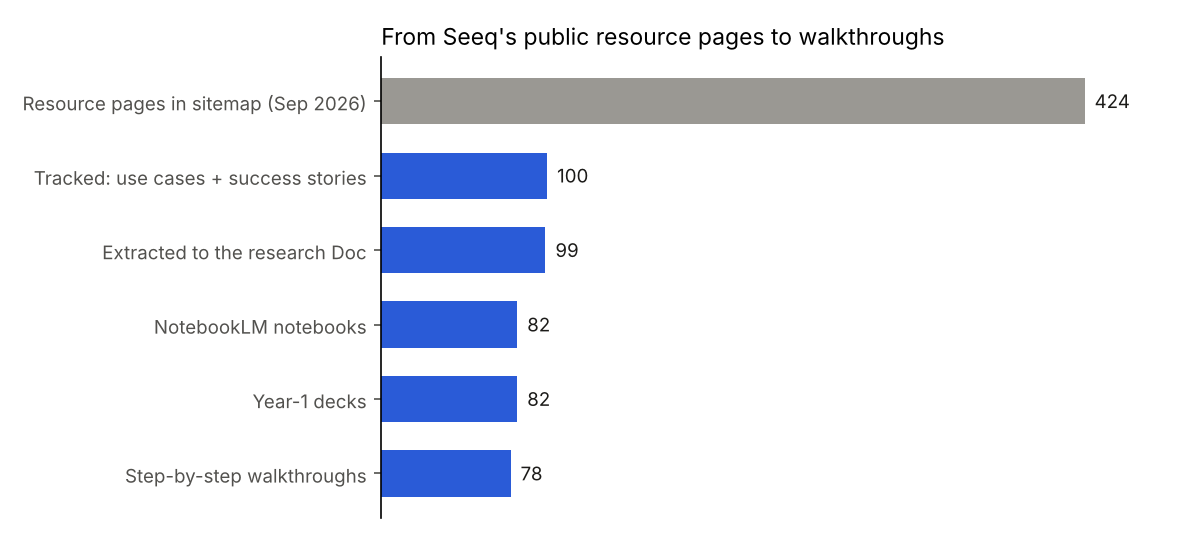

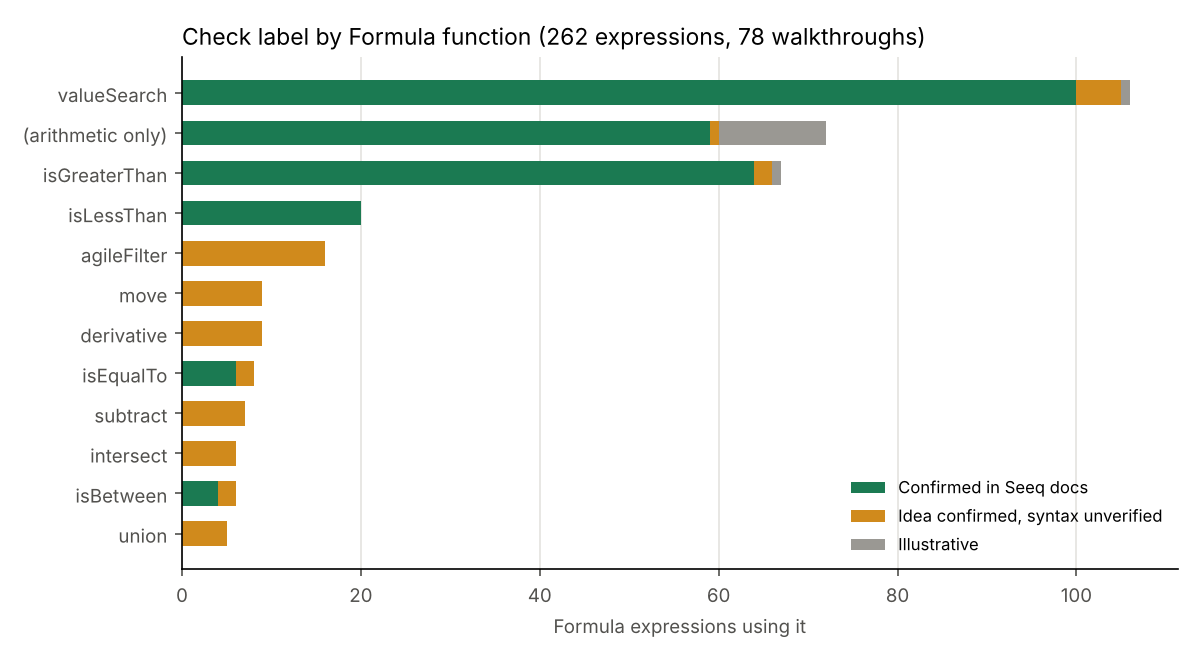

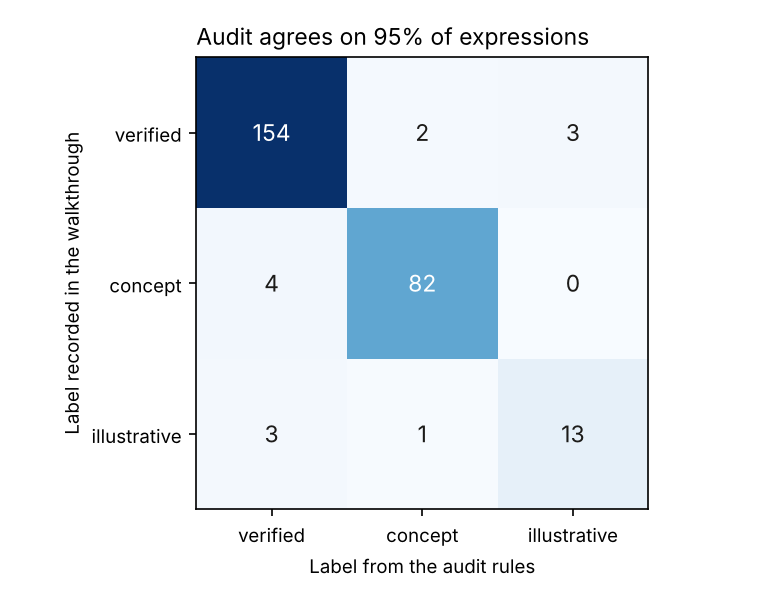

In [8]:
import main
m = main.run_all(quiet=True)
from IPython.display import Image, display
for f in ['pipeline_funnel', 'labels_by_function', 'label_audit']:
    display(Image(f'reports/figures/{f}.png', width=720))

## Serve it
`uvicorn src.api.app:app --reload`, then open http://127.0.0.1:8000/docs. The same call from Python:

In [9]:
from fastapi.testclient import TestClient
from src.api.app import app
TestClient(app).post('/check-formula', json={'formula': '$vibration.valueSearch(1day, isGreaterThan(4.5)).removeShorterThan(10min)'}).json()

{'label': 'concept',
 'meaning': 'Idea confirmed, syntax unverified',
 'reason': 'R2 shape not confirmed elsewhere: removeShorterThan(dur)',
 'signals': ['$vibration'],
 'call_shapes': ['isGreaterThan(num)',
  'removeShorterThan(dur)',
  'valueSearch(dur,call)'],
 'seen_in': ['aggregate-and-analyze-alarms',
  'aligning-data-for-calculations-and-correlation',
  'asset-utilization-oee-monitoring',
  'batch-quality-prediction',
  'batch-tracking-cycle-time-analysis',
  'bearing-failure-prediction',
  'biopharmaceutical-company-advanced-analytics-manufacturing-processes',
  'calculating-kpis-during-heats',
  'chemical-reactor-product-transition-optimization',
  'clean-in-place-cip-optimization']}